In [1]:
import pandas as pd
import os
import re
import biotite.structure as struc
import biotite.structure.io.pdbx as pdbx
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.lines import Line2D
import seaborn as sns
import numpy as np
import umap
import json
import glob
from scipy import stats

/net/well/pool/projects2/s253730/utils/Miniconda/envs/special_course/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Global variables, including analyse-dependant ones

In [112]:
pep_folder = "NLFR_analysis"
wt_seq = "NLFRRVWEL"
pep_short = "NLFR"
pep_file = "TCRneo_duplex_fingerprint_data_WT_TCR.tsv"
HLA_allele = "HLA-B*08:01"
cdr_definitions  = {
    "CDR1a": ("D", range(27, 33)), 
    "CDR2a": ("D", range(50, 57)), 
    "CDR3a": ("D", range(91, 104)),  
    "CDR1b": ("E", range(27, 32)), 
    "CDR2b": ("E", range(49, 55)), 
    "CDR3b": ("E", range(92, 104)),  
}
WT_label = "seed-8_sample-4"

# pep_folder = "EVDP_analysis"
# wt_seq = "EVDPIGHLY"
# pep_short = "EVDP"
# pep_file = "TCRA3_duplex_fingerprint_data_WT_TCR.tsv"
# HLA_allele = "HLA-A*01:01"
# cdr_definitions = {
#     "CDR1a": ("D", range(27, 33)),   
#     "CDR2a": ("D", range(50, 57)),   
#     "CDR3a": ("D", range(91, 104)), 
#     "CDR1b": ("E", range(27, 32)),   
#     "CDR2b": ("E", range(49, 55)),   
#     "CDR3b": ("E", range(92, 103)), 
# }
# WT_label = "seed-7_sample-2"

# pep_folder = "SLLQ_analysis"
# wt_seq = "SLLQHLIGL"
# pep_short = "SLLQ"
# pep_file = "PRAMEb_duplex_fingerprint_data_WT_TCR.tsv"
# HLA_allele = "HLA-A*02:01"
# cdr_definitions = {
#     "CDR1a": ("D", range(27, 33)),  
#     "CDR2a": ("D", range(50, 57)),  
#     "CDR3a": ("D", range(96, 105)), 
#     "CDR1b": ("E", range(27, 32)), 
#     "CDR2b": ("E", range(49, 55)), 
#     "CDR3b": ("E", range(94, 105)), 
# }
# WT_label = "seed-2_sample-1"

fig_folder = f"/net/well/pool/projects2/s253730/projects/pred_TCR_fingerprints/figures/{pep_folder}/"

peptide_chain = "C"

### Functions (visualization for heatmap, and correlation)

In [3]:
def plot_heatmap(matrix, labels, title, scale_center, fig_name = "", save_fig = False):

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    sns.heatmap(
        matrix,
        cmap="RdBu",
        center=scale_center,
        cbar_kws={"label": labels},
        ax=ax,
    )

    # Highlighting the WT sequence 
    for pos, aa in enumerate(wt_seq, start=1):
        if aa in matrix.index :
            y = matrix.index.get_loc(aa)
            ax.add_patch(
                patches.Rectangle(
                    (pos, y), 1, 1, fill=False, edgecolor="black", lw=2
                )
            )

    # Crossing out the residues without data
    for r_idx, aa in enumerate(matrix.index):
        for c_idx, pos in enumerate(matrix.columns):
            if pd.isna(matrix.loc[aa, pos]):
                ax.text(
                    c_idx + 0.5,
                    r_idx + 0.5,
                    "X",
                    ha="center",
                    va="center",
                    color="black",
                    fontsize=11,
                )

    ax.set_title(f"{title} - {HLA_allele} + {wt_seq}")
    ax.set_xlabel("Peptide_pos")
    ax.set_ylabel("Peptide_res")
    plt.tight_layout()

    if save_fig == True:
        plt.savefig(
          os.path.join(fig_folder, fig_name), dpi=300
      )
        
    plt.show()

def compute_columnwise_pcc(df_ref, df_pred):
    df_ref = df_ref.copy()
    df_pred = df_pred.copy()
    df_ref.columns = [int(c) for c in df_ref.columns]
    df_pred.columns = [int(c) for c in df_pred.columns]

    records = []
    common_cols = [col for col in df_ref.columns if col in df_pred.columns]

    for pos in common_cols:
        combined = pd.concat([df_ref[pos].rename("ref"), df_pred[pos].rename("pred")], axis=1).dropna()
        
        x = combined["ref"].astype(float)
        y = combined["pred"].astype(float)

        # Pearson requires at least 3 points and non-zero standard deviation
        if len(x) >= 3 and x.std() > 1e-8 and y.std() > 1e-8:
            p_res = stats.pearsonr(x, y)
            s_res = stats.spearmanr(x, y)
            pcc, pcc_pval = p_res.statistic, p_res.pvalue
            scc, scc_pval = s_res.statistic, s_res.pvalue
        else:
            pcc, pcc_pval, scc, scc_pval = np.nan, np.nan, np.nan, np.nan

        records.append({
            "Peptide_pos": pos,
            "PCC": pcc,
            "p_value_pcc": pcc_pval,
            "SCC": scc,
            "p_value_scc": scc_pval,
            "n_points": len(x)
        })

    return pd.DataFrame(records)


def plot_bars(ax, df, metric_name, pval_col, title):
    bars = ax.bar(
        df["Peptide_pos"],
        df[metric_name],
        color="#4C72B0",
        edgecolor="black",
        width=0.6,
        alpha=0.85
    )

    # Add significance stars
    for idx, row in df.iterrows():
        val = row[metric_name]
        pval = row[pval_col]
        if not np.isnan(val):
            star = "***" if pval < 0.001 else ("**" if pval < 0.01 else ("*" if pval < 0.05 else ""))
            y_pos = val + (0.02 if val >= 0 else -0.06)
            ax.text(
                row["Peptide_pos"],
                y_pos,
                star,
                ha="center",
                va="bottom" if val >= 0 else "top",
                fontsize=11,
                fontweight="bold"
            )

    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_ylim(-1.05, 1.15)
    ax.set_xticks(range(1, 10))
    ax.set_xlabel("Peptide position")
    ax.set_title(title, fontsize=12)





## PAE matrix analysis

### Function for obtaining the min PAE value for every .json file

In [133]:
def get_min_pae_mutant_to_cdr(json_path, mut_pos, pep_chain="C"):

  with open(json_path, "r") as f:
    conf = json.load(f)

  pae = np.array(conf["pae"])
  token_chains = np.array(conf["token_chain_ids"])
  token_res = np.array(conf["token_res_ids"])

  # Get the aimed peptide residue
  pep_mask = (token_chains == pep_chain) & (token_res == mut_pos)
  pep_indices = np.where(pep_mask)[0]
  target_idx = pep_indices[0]

  # Then getting the indexes of CDRs
  cdr_pairs = set()
  for chain, r_range in cdr_definitions.values():
    for r in r_range:
      cdr_pairs.add((chain, r))

  cdr_mask = [(c, r) in cdr_pairs for c, r in zip(token_chains, token_res, strict=False)]
  cdr_indices = np.where(cdr_mask)[0]

  # Finally, taking the minimum PAE value between selected peptide residue and all CDR chains
  pae_res_to_tcr = pae[target_idx, cdr_indices]
  pae_tcr_to_res = pae[cdr_indices, target_idx]

  min_val = min(float(pae_res_to_tcr.min()), float(pae_tcr_to_res.min()))

  return min_val

In [134]:
# # testing the function
# wt_file = os.path.join(metrics_folder, f"{pep_short}-P0_WT_confidences.json")

# # 1. Vérification du nombre de résidus CDR capturés
# with open(wt_file, "r") as f:
#   conf = json.load(f)

# token_chains = np.array(conf["token_chain_ids"])
# token_res = np.array(conf["token_res_ids"])

# cdr_pairs = set()
# for chain, r_range in cdr_definitions.values():
#   for r in r_range:
#     cdr_pairs.add((chain, r))

# cdr_indices = np.where(
#     [(c, r) in cdr_pairs for c, r in zip(token_chains, token_res, strict=False)]
# )[0]
# print(f"Nombre total de résidus CDR détectés : {len(cdr_indices)}")

# # 2. Test sur les 9 positions du peptide WT
# print("\nProfil PAE minimal WT -> CDRs :")
# for p in range(1, 10):
#   score = get_min_pae_mutant_to_cdr(wt_file, mut_pos=p)
#   print(f"  P{p}: {score:.2f} Å")
  


### Running through the whole folder

In [135]:
metrics_folder = f"/net/well/pool/projects2/s253730/projects/pred_TCR_fingerprints/data/{pep_folder}/af3_output_base3/metrics/"

# First, let's store all reference values for the wt peptide into a dictionnary
wt_file = os.path.join(metrics_folder, f"{pep_short}-P0_WT_confidences.json")
wt_ref_pae = {p: get_min_pae_mutant_to_cdr(wt_file, mut_pos=p) for p in range(1, 10)}

# Then, iterating over all other structures
records = []
all_json_files = glob.glob(os.path.join(metrics_folder, "*_confidences.json"))

for filepath in all_json_files:
    filename = os.path.basename(filepath)
    if "WT" in filename:
        continue

    # Extracting the position of the mutated amino acide (file format: NLFR-P3_A_confidences.json)
    match = re.search(r"P(\d+)_([A-Z])", filename)
    if not match:
        continue

    pos = int(match.group(1))
    mut_aa = match.group(2)

    # Axtracting the minimal PAE for this residue
    min_pae_mut = get_min_pae_mutant_to_cdr(filepath, mut_pos=pos)

    # taking a substraction and not a ratio becauser PAE is a distance so it can be close to 0
    delta_pae = wt_ref_pae[pos]- min_pae_mut 

    records.append({
        "Peptide_pos": pos,
        "Peptide_res": mut_aa,
        "min_pae": min_pae_mut,
        "delta_pae": delta_pae
    })

df_pae_results = pd.DataFrame(records)


### Matrix creation, visualization, and export

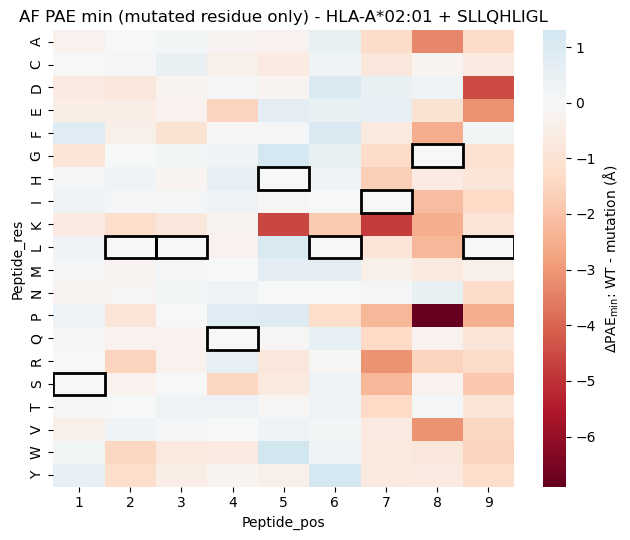

In [ ]:
alphabet_file = "../data/Matrices/alphabet"
alphabet = np.loadtxt("../data/Matrices/alphabet", dtype=str)

matrix_delta_pae = df_pae_results.pivot(index="Peptide_res", columns="Peptide_pos", values="delta_pae"
                                        ).reindex(index=alphabet, columns=range(1, 10))

# adding back wt value 
for i, wt_aa in enumerate(wt_seq, start=1):
  matrix_delta_pae.loc[wt_aa, i] = 0.0

matrix_delta_pae = matrix_delta_pae.sort_index()

label_pae = r'$\Delta\mathrm{PAE}_{\min}$: WT - mutation ($\mathrm{\AA}$)'
plot_heatmap(matrix_delta_pae, label_pae, "AF PAE min (mutated residue only)", 0.0 ) #, fig_name = heatmap_PAE, save_fig=True

# Export this heatmap
matrix_delta_pae.to_csv(f"../results/{pep_folder}/heatmaps/matrix_delta_pae.tsv", sep="\t")

### Import already computed PAE heatmaps

In [137]:
matrix_delta_pae = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_delta_pae.tsv", sep="\t", index_col=0)

### Correlation with previous AF metric and exp data

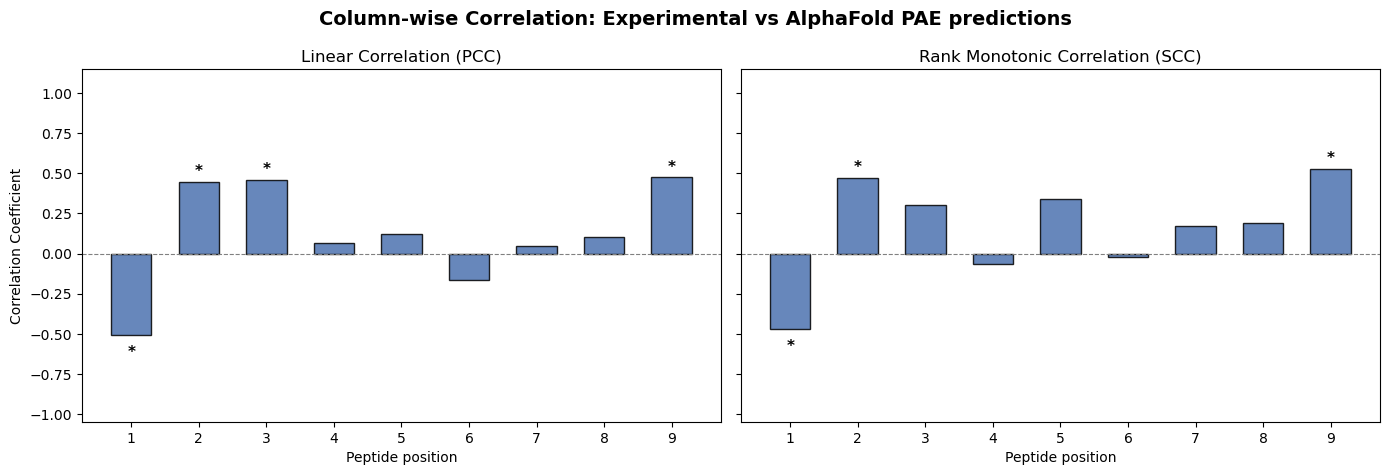

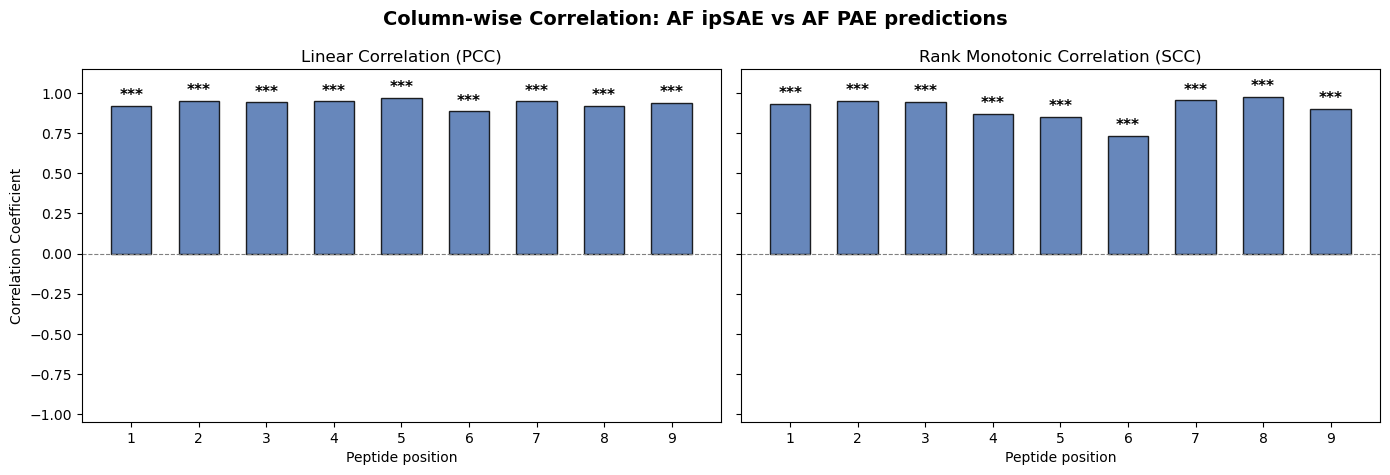

In [139]:
matrix_exp = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_exp_duplex.tsv", sep="\t", index_col=0)
matrix_af = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_af_interface.tsv", sep="\t", index_col=0)

pcc_pae_exp = compute_columnwise_pcc(matrix_exp, matrix_delta_pae)
pcc_pae_ipsae = compute_columnwise_pcc(matrix_af, matrix_delta_pae)


fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
plot_bars(
    ax1,
    pcc_pae_exp,
    metric_name="PCC",
    pval_col="p_value_pcc" if "p_value_pcc" in pcc_pae_exp.columns else "p_value",
    title="Linear Correlation (PCC)"
)
ax1.set_ylabel("Correlation Coefficient")

# Trace le deuxième graphique (SCC)
plot_bars(
    ax2,
    pcc_pae_exp,
    metric_name="SCC",
    pval_col="p_value_scc" if "p_value_scc" in pcc_pae_exp.columns else "p_value",
    title="Rank Monotonic Correlation (SCC)"
)

fig1.suptitle("Column-wise Correlation: Experimental vs AlphaFold PAE predictions", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


fig2, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
plot_bars(
    ax1,
    pcc_pae_ipsae,
    metric_name="PCC",
    pval_col="p_value_pcc" if "p_value_pcc" in pcc_pae_ipsae.columns else "p_value",
    title="Linear Correlation (PCC)"
)
ax1.set_ylabel("Correlation Coefficient")

# Trace le deuxième graphique (SCC)
plot_bars(
    ax2,
    pcc_pae_ipsae,
    metric_name="SCC",
    pval_col="p_value_scc" if "p_value_scc" in pcc_pae_ipsae.columns else "p_value",
    title="Rank Monotonic Correlation (SCC)"
)

fig2.suptitle("Column-wise Correlation: AF ipSAE vs AF PAE predictions", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

## ipSAE matrix analysis

## CDR-residue contact map

### Importing AF data and constants

In [5]:
struct_folder = f"/net/well/pool/projects2/s253730/projects/pred_TCR_fingerprints/data/{pep_folder}/af3_output_base3/structures"

# Importing this matrix again if we run this analysis without the PAE previous one
matrix_delta_pae = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_delta_pae.tsv", sep="\t", index_col=0)
metrics_folder = f"/net/well/pool/projects2/s253730/projects/pred_TCR_fingerprints/data/{pep_folder}/af3_output_base3/metrics/"

contact_cutoff = 4.0



### Functions

In [4]:
def extract_cdr_contact_matrix(cif_path, json_path):
  """
  Fonction that computes two CDR-residue contact summaries for a .cif structure file
  First output: a fine-grained matrix of every contact between peptide residues (P1-P9) x every CDR residue
  Second output: a summary of the matrix, CDR chain-wise (a 9x6 matrix)
  """

  cif_file = pdbx.CIFFile.read(str(cif_path))
  atoms = pdbx.get_structure(cif_file)[0]

  # Importing PAE data for later color scale
  with open(json_path, "r") as f:
    conf_data = json.load(f)

  pae_matrix = np.array(conf_data["pae"])
  token_chains = np.array(conf_data["token_chain_ids"])
  token_res = np.array(conf_data["token_res_ids"])

  # Fast mapping from (chain_id, res_id) to token index in AF3
  token_lookup = {
      (c, int(r)): idx for idx, (c, r) in enumerate(zip(token_chains, token_res))
  } 


  # Filter out hydrogen to work on heavy atoms
  heavy = atoms[atoms.element != "H"]

  # Peptide atoms
  pep_atoms = heavy[heavy.chain_id == peptide_chain]
  pep_res_ids = sorted(np.unique(pep_atoms.res_id))

  fine_records = []
  summary_records = []

  for p_pos, p_res in enumerate(pep_res_ids, start=1):
    p_coords = pep_atoms[pep_atoms.res_id == p_res].coord
    p_token = token_lookup.get((peptide_chain, int(p_res)))

    summary_row = {"peptide_pos": f"P{p_pos}"}

    for cdr_name, (chain_id, res_range) in cdr_definitions.items():
      loop_contacts = 0
      loop_min_dist = float("inf")

      for cdr_res in res_range:
        cdr_res_atoms = heavy[
            (heavy.chain_id == chain_id) & (heavy.res_id == cdr_res)
        ]
        if len(cdr_res_atoms) == 0:
          continue

        # Computing minimal distance between peptide residu and CDR residue (heavy atoms only)
        dists = cdist(p_coords, cdr_res_atoms.coord)
        min_d = dists.min()
        is_contact = int(min_d <= contact_cutoff)

        # Retrieve bidirectional local PAE if token is available
        cdr_token = token_lookup.get((chain_id, int(cdr_res)))
        if p_token is not None and cdr_token is not None:
          pair_pae = min(
              pae_matrix[p_token, cdr_token], pae_matrix[cdr_token, p_token]
          )
        else:
          pair_pae = np.nan

        fine_records.append({
            "peptide_pos": f"P{p_pos}",
            "cdr_loop": cdr_name,
            "cdr_res_id": cdr_res,
            "cdr_res_label": f"{cdr_name}_{cdr_res}",
            "min_distance": min_d,
            "contact": is_contact,
            "pae": pair_pae,
        })

        if is_contact:
          loop_contacts += 1
        if min_d < loop_min_dist:
          loop_min_dist = min_d

      summary_row[cdr_name] = loop_contacts
      summary_row[f"{cdr_name}_min_dist"] = loop_min_dist

    summary_records.append(summary_row)

  df_fine = pd.DataFrame(fine_records)
  df_summary = pd.DataFrame(summary_records).set_index("peptide_pos")

  return df_fine, df_summary

def plot_full_peptide(fine_dict, pos_aa, save_fig=False):

  pep_key = [k for k in fine_dict.keys() if pos_aa in k][0]
  df_fine = fine_dict[pep_key]

  df_fine["pae_contact"] = df_fine["pae"].where(df_fine["contact"] == 1, np.nan)

  # Pivot : ligns = P1 to P9, columns = CDR residues
  pep_order = [f"P{i}" for i in range(1, 10)]
  mat_fine = df_fine.pivot(
      index="peptide_pos", columns="cdr_res_label", values="pae_contact"
  ).reindex(index=pep_order)

  # Reorder CDR columns 
  loop_order = ["CDR1a", "CDR2a", "CDR3a", "CDR1b", "CDR2b", "CDR3b"]


  def sort_cdr_key(col_name):
    # Ex: "CDR3_alpha_95" -> loop = "CDR3_alpha", res_id = 95
    parts = col_name.rsplit("_", 1)
    loop = parts[0]
    res_id = int(parts[1])
    loop_idx = loop_order.index(loop) if loop in loop_order else 99
    return (loop_idx, res_id)

  ordered_cols = sorted(mat_fine.columns, key=sort_cdr_key)
  mat_fine = mat_fine.reindex(columns=ordered_cols)

  wt_key = [k for k in fine_dict.keys() if "WT" in k][0]
  df_wt = fine_dict[wt_key]
  mat_wt_contact = (
      df_wt.pivot(
          index="peptide_pos", columns="cdr_res_label", values="contact"
      )
      .reindex(index=pep_order, columns=ordered_cols)
      .fillna(0)
      .astype(int)
  )

  fig, ax = plt.subplots(figsize=(17, 5))
  sns.heatmap(
      mat_fine,
      cmap="viridis_r",
      vmin=0.0,
      vmax=15.0,
      cbar=True,
      cbar_kws={"label": r"Local PAE ($\mathrm{\AA}$)"},
      linewidths=0.5,
      linecolor="lightgray",
      ax=ax,
  )

  # Bringing a visual separation between CDR loops
  loop_names = [c.rsplit("_", 1)[0] for c in ordered_cols]
  boundaries = [0]
  for i in range(1, len(loop_names)):
    if loop_names[i] != loop_names[i - 1]:
      boundaries.append(i)
  boundaries.append(len(loop_names))

  for i in range(len(boundaries) - 1):
    start, end = boundaries[i], boundaries[i + 1]
    loop_name = loop_names[start]

    # Vertical separator between loops (thicker between alpha and beta)
    if start > 0:
      is_chain_switch = (
          "a" in loop_names[start - 1] and "b" in loop_names[start]
      )
      ax.axvline(
          start,
          color="black" if is_chain_switch else "#555555",
          linewidth=2.5 if is_chain_switch else 1.2,
          linestyle="-" if is_chain_switch else "--",
      )

    # Loop label centered above each section
    mid = (start + end) / 2
    ax.text(
        mid,
        -0.4,
        loop_name,
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
        color="#1a252f"
        )
    


  # Overlaying WT fantom contact-map
  n_rows, n_cols = mat_wt_contact.shape
  for r_idx in range(n_rows):
    for c_idx in range(n_cols):
      if mat_wt_contact.iloc[r_idx, c_idx] == 1:
        rect = patches.Rectangle(
            (c_idx, r_idx),
            1,
            1,
            linewidth=1,
            edgecolor="black",
            facecolor="none",
            linestyle="--",
            zorder=3,
        )
        ax.add_patch(rect)

  # Legend for this WT fingerprint
  wt_proxy = Line2D(
      [0],
      [0],
      color="black",
      linestyle="--",
      linewidth=1.4,
      label="WT contact",
  )
  ax.legend(
      handles=[wt_proxy],
      loc="upper right",
      bbox_to_anchor=(1.0, 1.25),
      frameon=True,
      facecolor="white",
      edgecolor="none",
      fontsize=9,
  )

  ax.set_title(
      f"{pep_key} Fine-grained Residue Contact Map ({pep_short})\nThreshold < {contact_cutoff} Å",
      fontsize=13,
      pad=22,
  )
  ax.set_xlabel("CDR Residues", fontsize=11)
  ax.set_ylabel("Peptide Position", fontsize=11)
  ax.tick_params(axis="x", rotation=90, labelsize=8)
  plt.tight_layout()

  if save_fig == True:
    plt.savefig(
      os.path.join(fig_folder, f"{pep_key}_fine_contact_map.png"), dpi=300
  )
    
  plt.show()

def plot_mean_contact(summary_dict, pos, save_fig=False):
  p_mutants = [k for k in summary_dict.keys() if f"{pos}_" in k]

  # Extracting the binary value (contact with each CDR) for all mutants of a given residue
  cdr_cols = list(cdr_definitions.keys())
  p_matrices = [
      summary_dict[k].loc[["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8", "P9"], cdr_cols]
      for k in p_mutants
  ]

  # Computing mean matrice of contact
  mean_p_matrix = sum(p_matrices) / len(p_matrices)

  # Frequency heatmap
  plt.figure(figsize=(8, 6))
  sns.heatmap(
      mean_p_matrix,
      annot=True,
      fmt=".1f",
      cmap="YlGnBu",
      vmin=0,
      cbar_kws={"label": "Mean Contact Counts"},
  )
  plt.title(
      f"Mean Contact Counts across all {pos} Mutants (n={len(p_mutants)})\n{pep_short}",
      fontsize=13,
  )
  plt.xlabel("CDR Loop", fontsize=11)
  plt.ylabel("Peptide Position", fontsize=11)
  plt.tight_layout()

  if save_fig == True:
      plt.savefig(
        os.path.join(fig_folder, f"{pos}_mean_contacts.png"), dpi=300
    )
      
  plt.show()

### Computing all contacts

In [6]:
all_summaries = {}
all_fines = {}

for fname in sorted(os.listdir(struct_folder)):
  if not fname.endswith(".cif"):
    continue

  mut_id = fname.replace(f"{pep_short}-", "").replace(".cif", "")
  cif_path = os.path.join(struct_folder, fname)

  base_prefix = fname.replace(".cif", "")
  metric_path = os.path.join(metrics_folder, f"{base_prefix}_confidences.json")
  

  df_fine, df_summary = extract_cdr_contact_matrix(cif_path, metric_path)
  all_fines[mut_id] = df_fine
  all_summaries[mut_id] = df_summary

/net/well/pool/projects2/s253730/utils/Miniconda/envs/special_course/lib/python3.10/site-packages/biotite/structure/io/pdbx/convert.py:435: UserWarning: Attribute 'auth_comp_id' not found within 'atom_site' category. The fallback attribute 'label_comp_id' will be used instead
  warnings.warn(
/net/well/pool/projects2/s253730/utils/Miniconda/envs/special_course/lib/python3.10/site-packages/biotite/structure/io/pdbx/convert.py:435: UserWarning: Attribute 'auth_atom_id' not found within 'atom_site' category. The fallback attribute 'label_atom_id' will be used instead
  warnings.warn(


### Visualization

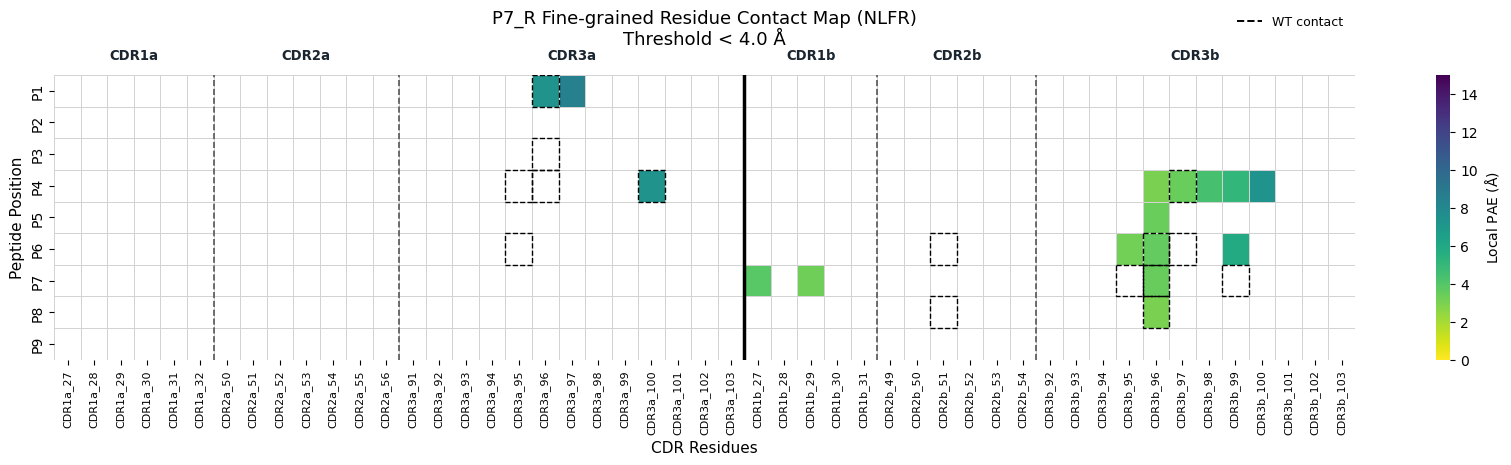

In [8]:
plot_full_peptide(all_fines, "P7_R")

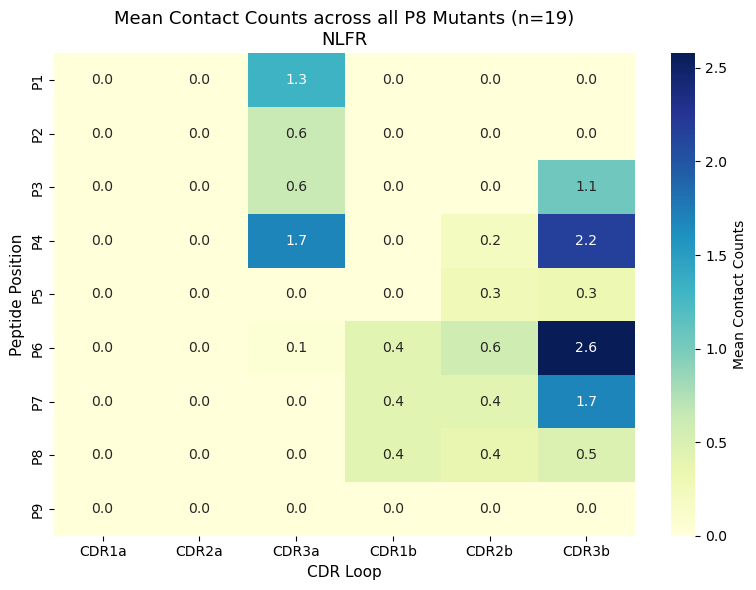

In [160]:
plot_mean_contact(all_summaries, "P8")

## Docking analysis

**To obtain docking data, run the docking.sh file in src folder first**

### Importing docking data and reconstruting a named dataframe

In [116]:
dock_folder = f"/net/well/pool/projects2/s253730/projects/pred_TCR_fingerprints/data/{pep_folder}/af3_output_base3/WT_docking_output"
# dock_folder = f"/net/well/pool/projects2/s253730/projects/pred_TCR_fingerprints/data/{pep_folder}/af3_output_base3/docking_output"
df_info = pd.read_table(f"{dock_folder}/parse_output.tsv")
labels = [path.split("/")[-1].replace(".pdb", "") for path in df_info["pdbfile"]]

dock_res = np.loadtxt(f"{dock_folder}/docking_rmsds.tsv")

df_dist = pd.DataFrame(dock_res, index=labels, columns=labels)



In [117]:
df_dist.head()

,seed-10_sample-0,seed-10_sample-1,seed-10_sample-2,seed-10_sample-3,seed-10_sample-4,seed-1_sample-0,seed-1_sample-1,seed-1_sample-2,seed-1_sample-3,seed-1_sample-4,...,seed-8_sample-0,seed-8_sample-1,seed-8_sample-2,seed-8_sample-3,seed-8_sample-4,seed-9_sample-0,seed-9_sample-1,seed-9_sample-2,seed-9_sample-3,seed-9_sample-4
seed-10_sample-0,0.000000,1.315691,1.203939,1.652789,1.676665,2.389785,2.416368,2.217593,2.512499,2.850077,...,2.661040,2.280348,2.583398,2.669670,2.817214,2.671611,2.200319,2.274024,2.580069,2.471706
seed-10_sample-1,1.315691,0.000000,1.949509,1.858834,0.962496,1.343596,1.316722,1.152103,1.488685,1.863505,...,1.556208,1.324918,1.551436,1.646844,1.694891,2.247652,1.934240,1.616792,2.190440,2.334747
seed-10_sample-2,1.203939,1.949509,0.000000,1.799771,2.545134,2.959079,2.945925,2.889462,3.081118,3.510973,...,3.217170,2.912037,3.191461,3.159303,3.398707,2.944779,2.601094,2.397051,2.898130,2.673689
seed-10_sample-3,1.652789,1.858834,1.799771,0.000000,1.833760,2.532604,2.915950,2.684719,2.765120,3.126437,...,2.850767,2.696623,2.822206,2.790002,3.246643,1.379979,1.031292,1.429813,1.251942,0.997960
seed-10_sample-4,1.676665,0.962496,2.545134,1.833760,0.000000,1.178968,1.559859,1.131484,1.407051,1.578312,...,1.479097,1.255122,1.365861,1.530042,1.766925,1.924905,1.593578,1.710205,1.854648,2.097136


### Importing metadata for visualization

In [60]:
# Importing experimental, AF3 and pMHC data to use the UMI count as a color scheme for the UMAP

matrix_exp = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_exp_duplex.tsv", sep="\t", index_col=0)
matrix_af = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_af_interface.tsv", sep="\t", index_col=0)
matrix_pmhc = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_score_netmhcpan.tsv", sep="\t", index_col=0)

# print(matrix_exp.head())
# print(matrix_af.head())
# print(matrix_pmhc.head())



In [96]:
# WT analysis: we have to retrieve all ipSAE scores individually

df_wt_scores = pd.read_csv(f"../data/{pep_folder}/af3_output_base3/WT_ipsae_scores.csv")
score_lookup = df_wt_scores.set_index("seed_sample")["ipsae_score"] # to map scores via the label value of df_plot

### UMAP-like visualisation based on the distance matrix

In [119]:
reducer = umap.UMAP(
    metric="precomputed",
    n_neighbors=15,  
    min_dist=0.1,  
    random_state=42,  
)


embedding = reducer.fit_transform(df_dist)

# preparing data for visualization
df_plot = pd.DataFrame(
    {
        "UMAP1": embedding[:, 0],
        "UMAP2": embedding[:, 1],
        "label": labels,
    }
)

# NLFR-P1_A: position "P1", mutant "A"
# NLFR-P0_WT: position "P0", mutant "WT"
# df_plot["position"] = df_plot["label"].apply(
#     lambda x: x.split("-")[1].split("_")[0] if "-" in x else "Other"
# )
# df_plot["mutation"] = df_plot["label"].apply(
#     lambda x: x.split("_")[-1] if "_" in x else "WT"
# )
# df_plot["is_wt"] = df_plot["mutation"] == "WT"


# Case of WT structures: seed-10_sample-0: seed "10", sample "0"
df_plot["seed"] = df_plot["label"].apply(
    lambda x: x.split("-")[1].split("_")[0] if "-" in x else "Other"
)
df_plot["sample"] = df_plot["label"].apply(
    lambda x: x.split("-")[2] if "-" in x else "Other"
)
df_plot["is_wt"] = df_plot["label"] == WT_label


# matrix_exp.columns = [int(str(c).replace("P", "")) for c in matrix_exp.columns]
# matrix_af.columns = [int(str(c).replace("P", "")) for c in matrix_af.columns]
# matrix_pmhc.columns = [int(str(c).replace("P", "")) for c in matrix_pmhc.columns]

# Function to extract metadata from an imported matric (format: AA in index, position in columns)
def get_val(row, mat):
  if row["is_wt"] or row["position"] == "Other":
    return np.nan
  try:
    pos = int(row["position"].replace("P", ""))
    return mat.loc[row["mutation"], pos]
  except (KeyError, ValueError):
    return np.nan

  
# df_plot["log2_mean_umi"] = df_plot.apply(get_val, mat=matrix_exp, axis=1)
# df_plot["ipsae_score"] = df_plot.apply(get_val, mat=matrix_af, axis=1)
# df_plot["netMHCpan"] = df_plot.apply(get_val, mat=matrix_pmhc, axis=1)

# for WT structures:
df_plot["ipsae_score"] = df_plot["label"].map(score_lookup)

/net/well/pool/projects2/s253730/utils/Miniconda/envs/special_course/lib/python3.10/site-packages/umap/umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
/net/well/pool/projects2/s253730/utils/Miniconda/envs/special_course/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


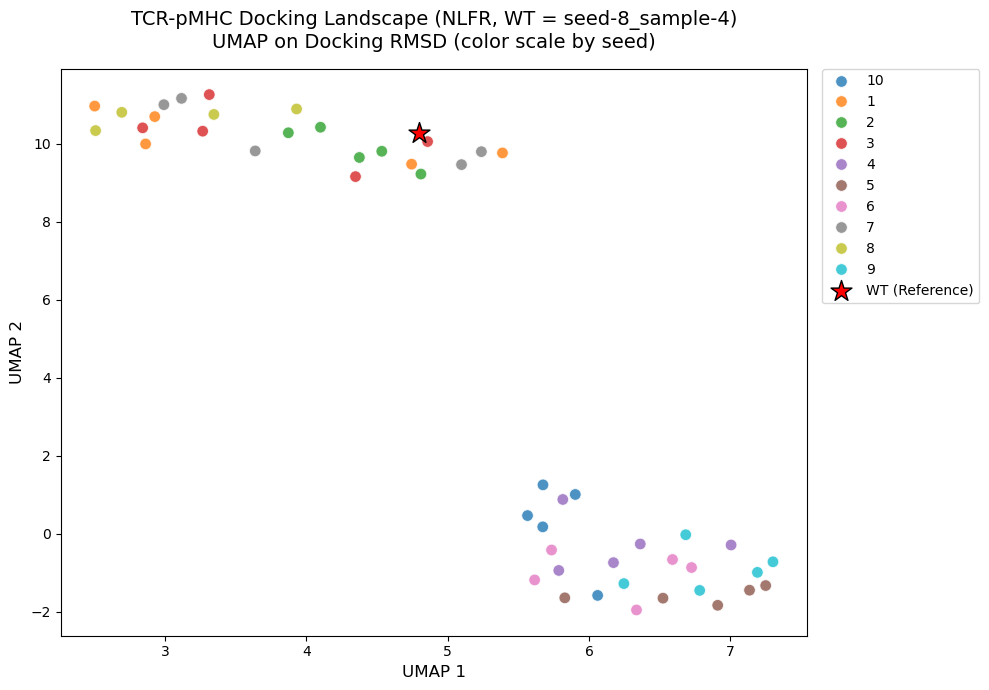

In [120]:
# color_scale = "log2_mean_umi"
# color_scale = "ipsae_score" 
# color_scale = "netMHCpan"
# color_scale = "position" # better to comment out the viridis palette for this one

# if working with WT structures
color_scale = "seed" # better to comment out the viridis palette for this one
# color_scale = "ipsae_score" 

# Visualization
plt.figure(figsize=(10, 7))

# Color mutants by their position
sns.scatterplot(
    data=df_plot[~df_plot["is_wt"]],
    # data=df_plot[~df_plot["is_wt"] & ~df_plot["is_alt"]],
    x="UMAP1",
    y="UMAP2",
    hue=color_scale,
    # palette = "viridis", 
    s=70,
    alpha=0.8,
)

# Highlighting the WT peptide
wt_data = df_plot[df_plot["is_wt"]]
if not wt_data.empty:
  plt.scatter(
      wt_data["UMAP1"],
      wt_data["UMAP2"],
      color="red",
      marker="*",
      s=250,
      label="WT (Reference)",
      edgecolor="black",
      zorder=10,
  )

# Highlight alternate cluster
# sns.scatterplot(
#     data=df_plot[df_plot["is_alt"]],
#     x="UMAP1",
#     y="UMAP2",
#     color="darkorange",
#     s=90,
#     edgecolor="black",
#     label=f"Alternative cluster (n={df_plot['is_alt'].sum()})",
# )

plt.title(
    # f"TCR-pMHC Docking Landscape ({pep_short})\nUMAP on Docking RMSD (color scale by {color_scale})"
    f"TCR-pMHC Docking Landscape ({pep_short}, WT = {WT_label})\nUMAP on Docking RMSD (color scale by {color_scale})",
    fontsize=14,
    pad=15,
)
plt.xlabel("UMAP 1", fontsize=12)
plt.ylabel("UMAP 2", fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()

# Saving figure
# plt.savefig(os.path.join(fig_folder, f"UMAP_like_{color_scale}.png"), dpi=300)
# plt.savefig(os.path.join(fig_folder, f"UMAP_like_WT_diversity_ipsae.png"), dpi=300)

plt.show()

### Plotting mean-distance of RMSD matrix
Quick maths on pairwise-distance matrix, to identify variability within structures (useful for WT study)

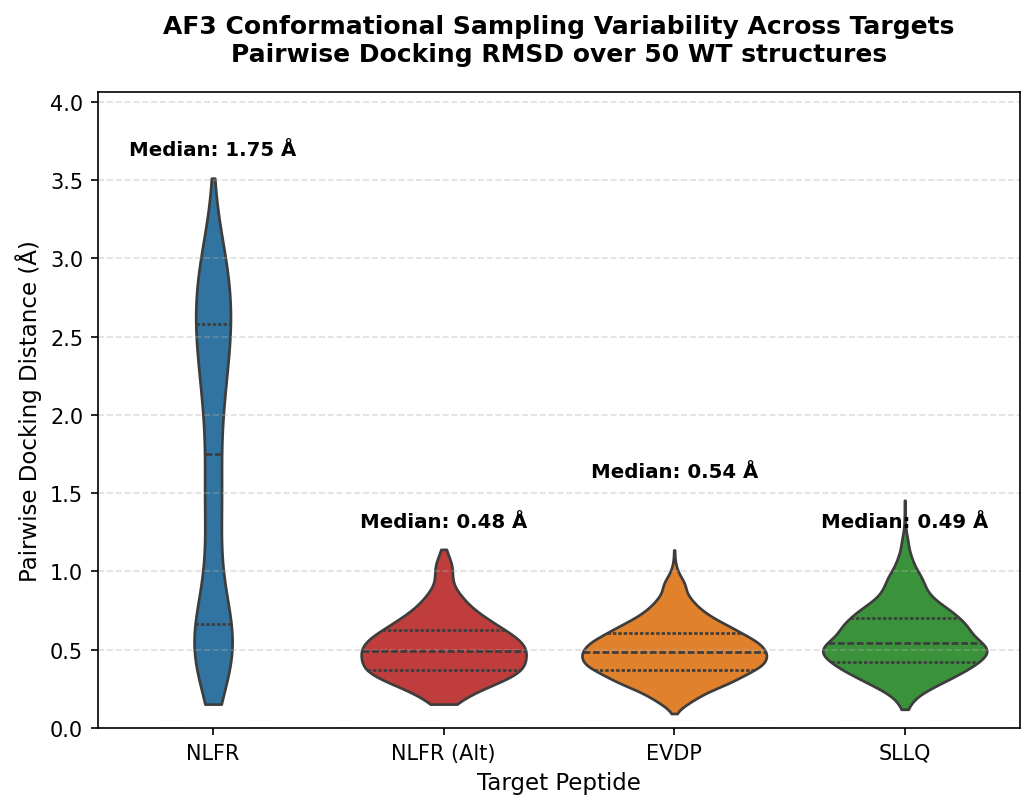

In [126]:
targets = [
    {"name": "NLFR", "folder": "NLFR_analysis"},
    {"name": "EVDP", "folder": "EVDP_analysis"},
    {"name": "SLLQ", "folder": "SLLQ_analysis"},
]

data_records = []
summary_stats = []

for tgt in targets:
  pep_name = tgt["name"]
  target_folder = tgt["folder"]

  dock_folder = f"/net/well/pool/projects2/s253730/projects/pred_TCR_fingerprints/data/{target_folder}/af3_output_base3/WT_docking_output"
#   dock_folder = f"/net/well/pool/projects2/s253730/projects/pred_TCR_fingerprints/data/{target_folder}/af3_output_base3/docking_output"
  rmsd_file = f"{dock_folder}/docking_rmsds.tsv"

  dock_res = np.loadtxt(rmsd_file)
  pairwise_dists = dock_res[np.triu_indices(len(dock_res), k=1)]

  for d in pairwise_dists:
    data_records.append({"Dataset": pep_name, "RMSD": d})

  summary_stats.append({
      "Dataset": pep_name,
      "Mean": np.mean(pairwise_dists),
      "Median": np.median(pairwise_dists),
      "P95": np.percentile(pairwise_dists, 95),
      "Max": np.max(pairwise_dists),
  })

df_violin = pd.DataFrame(data_records)
df_stats = pd.DataFrame(summary_stats)

# If we want to add another customed dataset 
alt_name = "NLFR (Alt)"  
alt_mat = np.asarray(df_alt)
alt_dists = alt_mat[np.triu_indices(len(alt_mat), k=1)]

df_violin_alt = pd.DataFrame({"Dataset": alt_name, "RMSD": alt_dists})
df_violin = pd.concat([df_violin, df_violin_alt], ignore_index=True)

df_stats_alt = pd.DataFrame([{
    "Dataset": alt_name,
    "Mean": np.mean(alt_dists),
    "Median": np.median(alt_dists),
    "P95": np.percentile(alt_dists, 95),
    "Max": np.max(alt_dists),
}])
df_stats = pd.concat([df_stats, df_stats_alt], ignore_index=True)

fig, ax = plt.subplots(figsize=(7, 5.5), dpi=150)

plot_order = ["NLFR", "NLFR (Alt)", "EVDP", "SLLQ"]

sns.violinplot(
    data=df_violin,
    x="Dataset",
    y="RMSD",
    order = plot_order,
    legend=False,
    hue="Dataset",
    common_norm=True,
    inner="quartile",
    density_norm="area",
    cut=0,
    linewidth=1.3,
    ax=ax,
)

ax.set_title(
    "AF3 Conformational Sampling Variability Across Targets\n"
    "Pairwise Docking RMSD over 50 WT structures",
    fontsize=12,
    weight="bold",
    pad=15,
)
ax.set_ylabel("Pairwise Docking Distance (Å)", fontsize=11)
ax.set_xlabel("Target Peptide", fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.4)


y_max_global = df_violin["RMSD"].max()
ax.set_ylim(0, y_max_global + 0.55)

medians = df_violin.groupby("Dataset")["RMSD"].median()
maxs = df_violin.groupby("Dataset")["RMSD"].max()

for i, name in enumerate(df_violin["Dataset"].unique()):
    ax.text(
        i,
        maxs[name] + 0.12,
        f"Median: {medians[name]:.2f} Å",
        ha="center",
        va="bottom",
        fontsize=9.5,
        weight="bold",
    )

plt.tight_layout()
# plt.savefig("../figures/WT_diversity_vplot.png", dpi=300)
plt.show()

### Focus on alternate cluster (NLFR_analysis)

A small group of structures seems deviated from the WT, while having both good experimental and ipsae scores. Let's try to investigate that

In [10]:
mask_alt = (
    (df_plot["UMAP1"] >= 2.5)
    & (df_plot["UMAP1"] <= 4.2)
    & (df_plot["UMAP2"] <= -1.0)
)
df_plot["is_alt"] = mask_alt
alt_cluster = df_plot.loc[df_plot["is_alt"], ]

print(alt_cluster)



Empty DataFrame
Columns: [UMAP1, UMAP2, label, seed, sample, is_wt, is_alt]
Index: []


Ideas with this data: check fine-grained contact map

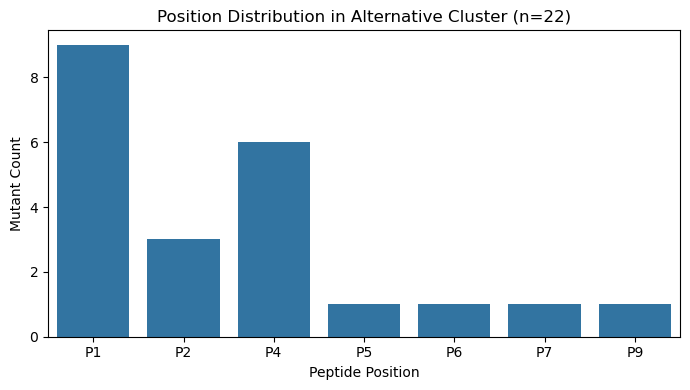

In [172]:
alt_df = df_plot[df_plot["is_alt"]]

plt.figure(figsize=(7, 4))
sns.countplot(
    data=alt_df,
    x="position",
    order=[f"P{i}" for i in range(1, 10) if f"P{i}" in alt_df["position"].values]
)
plt.title(f"Position Distribution in Alternative Cluster (n={len(alt_df)})")
plt.xlabel("Peptide Position")
plt.ylabel("Mutant Count")
plt.tight_layout()
plt.show()

Top alternative binder: NLFR-P1_Y (log2_UMI = 4.77, ipSAE = 0.84)


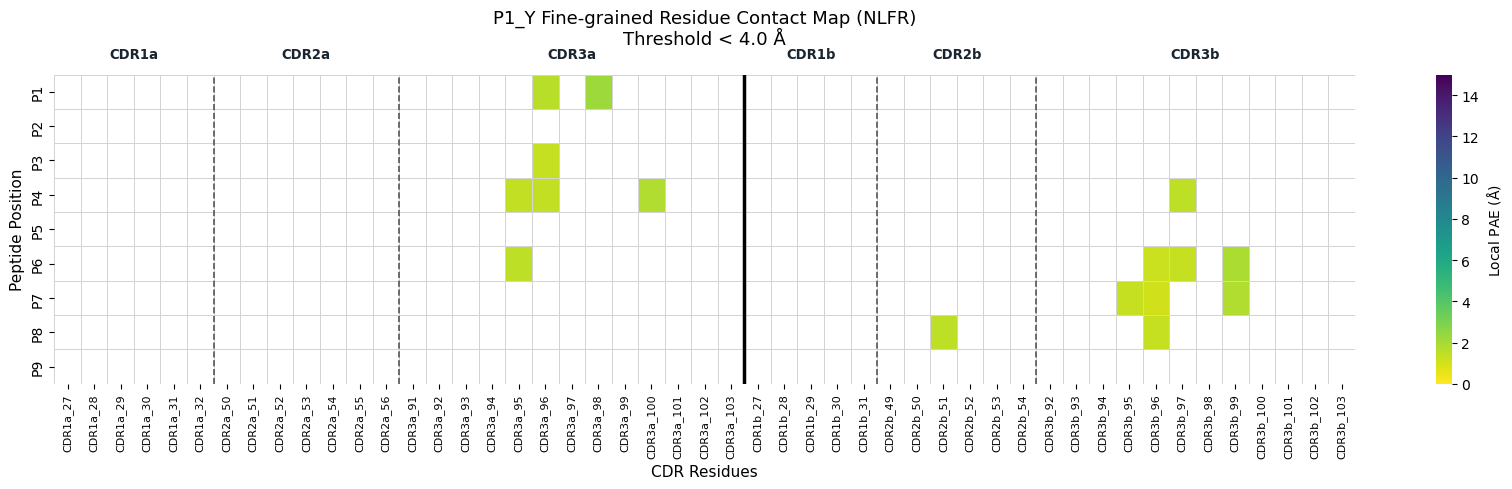

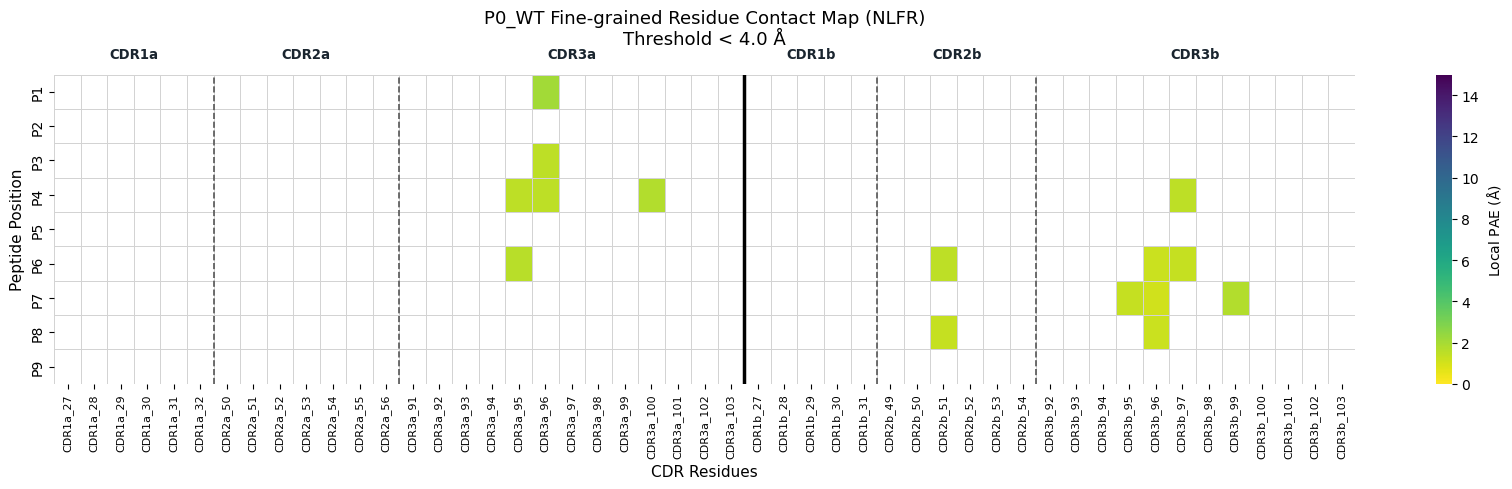

In [175]:
# Take the fine-grained contact map of best binder
best_binder = alt_df.sort_values(by="log2_mean_umi", ascending=False).iloc[0]
print(f"Top alternative binder: {best_binder['label']} (log2_UMI = {best_binder['log2_mean_umi']:.2f}, ipSAE = {best_binder['ipsae_score']:.2f})")

best_label = best_binder['label'].split('_')[-1]

plot_full_peptide(all_fines, best_label)
plot_full_peptide(all_fines, "WT")

### WT NLFR analysis: focus on upper-left corner cluster

In [ ]:
mask_alt = ((df_plot["UMAP2"] >= 6))

df_plot["is_alt"] = mask_alt
alt_cluster = df_plot.loc[df_plot["is_alt"], ]
alt_cluster_label = alt_cluster["label"]
df_alt = pd.DataFrame(dock_res, index=labels, columns=labels).loc[alt_cluster_label, alt_cluster_label]

#new version of the df_dist: so that we can run the UMAP analysis on the alternate cluister only
# df_dist = df_alt.copy()
# labels = alt_cluster_label #just to fit the syntax used in the UMAP code so far

                 seed-1_sample-0  seed-1_sample-1  seed-1_sample-2  \
seed-1_sample-0         0.000000         0.774273         0.581720   
seed-1_sample-1         0.774273         0.000000         0.582257   
seed-1_sample-2         0.581720         0.582257         0.000000   
seed-1_sample-3         0.358294         0.708439         0.633256   
seed-1_sample-4         0.660462         0.955019         0.785710   
seed-2_sample-0         0.611149         0.517082         0.483423   
seed-2_sample-1         0.668170         0.713583         0.785172   
seed-2_sample-2         0.572941         0.603918         0.575510   
seed-2_sample-3         0.586194         0.517756         0.411025   
seed-2_sample-4         0.618047         0.439656         0.284420   
seed-3_sample-0         0.711017         0.442049         0.491789   
seed-3_sample-1         0.608372         0.571277         0.356784   
seed-3_sample-2         0.345987         0.686139         0.477627   
seed-3_sample-3     